# Regressão Linear

## Introdução

Análise de regressão é um dos modos mais simples e mais utilizados de predição. É um método estatístico fundamental para iniciar o entendimento de aprendizados de máquina e o ponto de partida para cientistas de dados.

Poderia ser um objeto de estudo de alguém quantos quilômetros um determinado carro percorre com determinada quantidade de combustível ou por quanto foi vendida uma casa com determinados metros quadrados de área construída. Mesmo carros de mesmo tipo e ano não terão o mesmo consumo; mesmo casas com a mesma metragem não terão o mesmo preço. `consumo` no caso dos carros e `preço` no caso das casas são variáveis que _dependem_ das outras (`quantidade de litros`, `metros quadrados`). As variáveis dependentes são também chamadas _resposta_. As variáveis sobre as quais temos controle, podendo escolher ou medir, são ditas variáveis _independentes_, _explanatórias_ ou _regressoras_. Podemos estabelecer uma relação entre as variáveis dependentes (_respostas_) e as variáveis independentes (_regressores_) através de um modelo que explique _como_ uma resposta se comporta dependendo de um regressor.

Modelos de regressão são muito valiosos por serem um dos meios mais comuns e simples de fazer inferência e predição. Também é importante para determinar quais fatores mais influenciam de modo significativo um resultado.

## Modelo

O modelo de regressão nos ajuda a fazer previsões sobre a __população__ baseadas em informações dos dados __amostrais__. O objetivo é explorar o relacionamento entre duas (ou mais) variáveis (atributos / _features_) de modo a ganhar informação sobre uma delas a partir do valor da(s) outra(s).

Amostra $\rightarrow$ Construção do modelo $\rightarrow$ Previsão sobre a __população__

Modelo de Regressão Linear:  
$Y_i = \beta_0 + \beta_1 X_i + \epsilon_i$

$Y_i$ - elemento _i_ da variável dependente $Y$  
$\beta_0$ - constante linear  
$\beta_1$ - coeficiente de inclinação  
$X_i$ - elemento _i_ da variável independente $X$  
$\epsilon_i$ - erro (do elemento _i_)

Como os parâmetros referem-se à população, são utilizadas letras gregas.

Equação da Regressão Linear:  
$y_i$ = $b_0 + b_1 x_i$  
$y_i$ - elemento _i_ estimado (predito)  
$b_0$ - constante linear estimada  
$b_1$ - coeficiente de inclinação estimado  
$x_i$ - elemento _i_ da variável independente amostral $x$  


Em R, `lm(fórmula, dados)`, a `fórmula` é do tipo "$y$ ~ $x_1 + x_2 + x_1:x_2$", por exemplo. 
As os termos $x_i$ são variáveis independentes e $y_i$ o valor predito pelo modelo.

Vamos utilizar o banco de dados `women` de R:

In [1]:
mlh <- women

A variável `weight` está em libras. Convertendo para $kgf$:

In [2]:
mlh$peso <- women$weight * 0.45
mlh$weight <- NULL

A variável `height` está em polegadas, convertendo para $m$:

In [3]:
mlh$altura <- women$height * 0.0253
mlh$height <- NULL

In [4]:
print(mlh)

    peso altura
1  51.75 1.4674
2  52.65 1.4927
3  54.00 1.5180
4  55.35 1.5433
5  56.70 1.5686
6  58.05 1.5939
7  59.40 1.6192
8  60.75 1.6445
9  62.55 1.6698
10 63.90 1.6951
11 65.70 1.7204
12 67.50 1.7457
13 69.30 1.7710
14 71.55 1.7963
15 73.80 1.8216


In [5]:
options(digits=3)
summary(mlh)

      peso          altura    
 Min.   :51.8   Min.   :1.47  
 1st Qu.:56.0   1st Qu.:1.56  
 Median :60.8   Median :1.64  
 Mean   :61.5   Mean   :1.64  
 3rd Qu.:66.6   3rd Qu.:1.73  
 Max.   :73.8   Max.   :1.82  

In [6]:
# criando função para dimensionar gráfico no Jupyter
library(repr)
grafdim <- function(x,y) { options(repr.plot.width=x, repr.plot.height=y) }

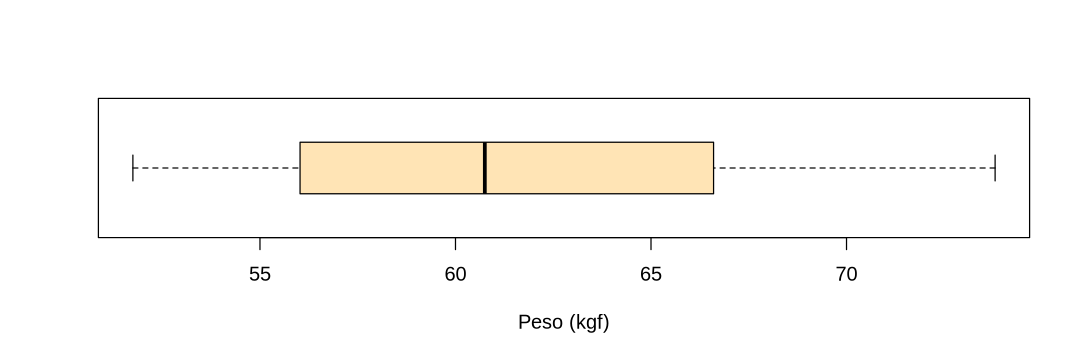

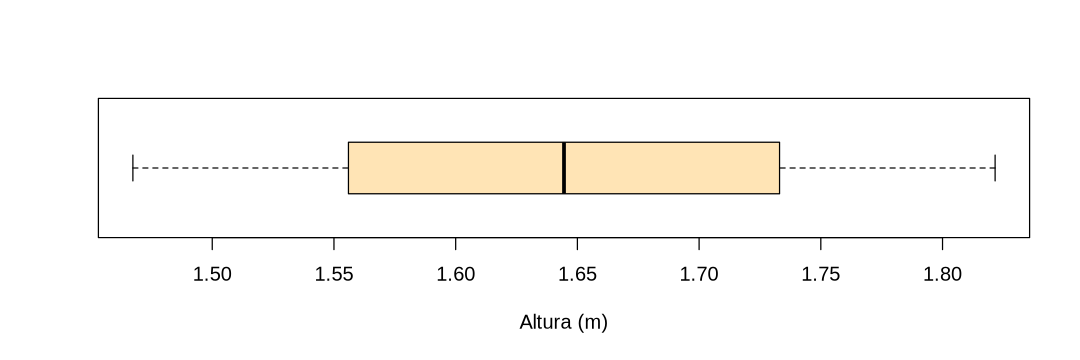

In [7]:
grafdim(9,3)
boxplot(mlh$peso, horizontal=TRUE, col="moccasin", xlab="Peso (kgf)")
boxplot(mlh$altura, horizontal=TRUE, col="moccasin", xlab="Altura (m)")

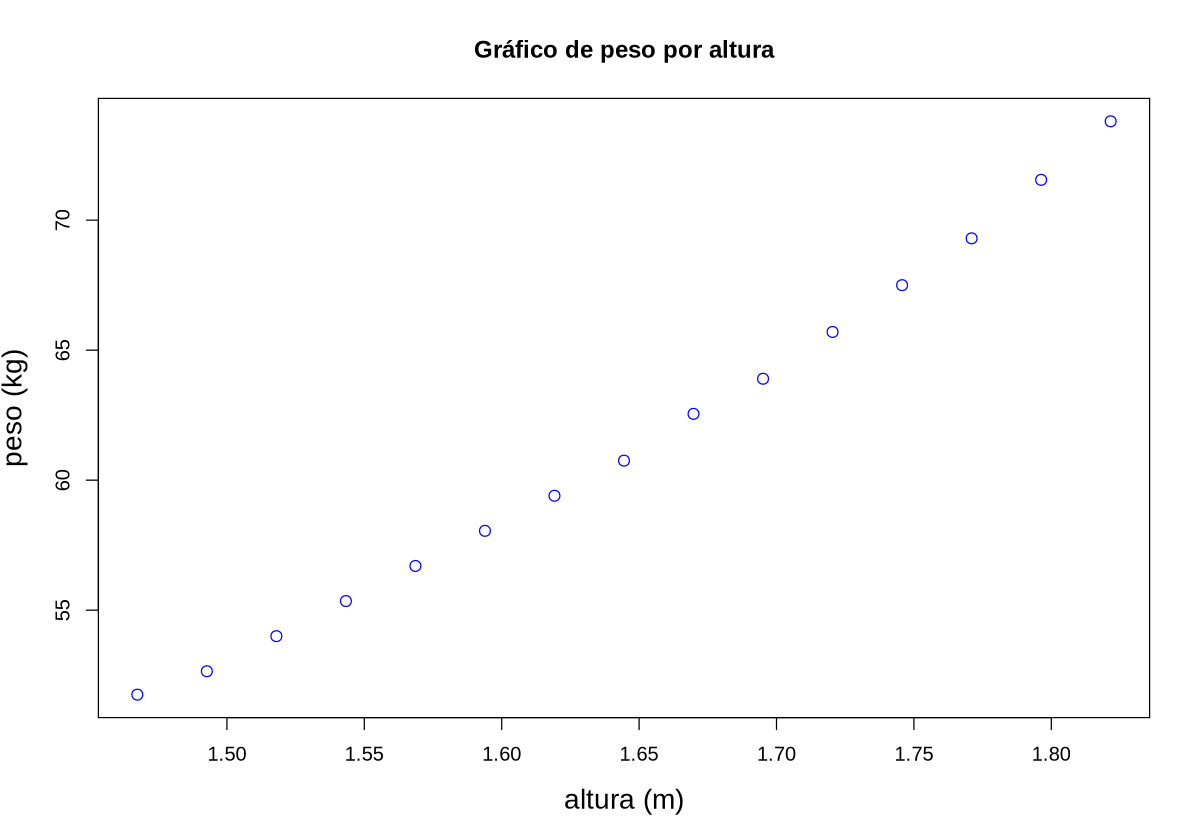

In [8]:
grafdim(10,7)
plot(mlh$altura, mlh$peso, col="blue", cex=1.2, cex.lab=1.4,
     xlab="altura (m)", ylab="peso (kg)", 
     main="Gráfico de peso por altura")

Construindo a regressão do peso em função da altura:

In [9]:
reg <- lm(formula=peso ~ altura, data=mlh)

In [10]:
reg


Call:
lm(formula = peso ~ altura, data = mlh)

Coefficients:
(Intercept)       altura  
      -39.4         61.4  


Os resultados dizem que a fórmula da regressão seria:  
`peso` = -39,4 + 61,4 ·`altura`  
Assim espera-se um aumento de 61,4 ($kg$) para cada 1 ($m$) de altura (ou 6,1 $kg$ para cada 10 $cm$).

In [11]:
summary(reg)


Call:
lm(formula = peso ~ altura, data = mlh)

Residuals:
   Min     1Q Median     3Q    Max 
-0.780 -0.510 -0.172  0.334  1.403 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)   -39.38       2.67   -14.7  1.7e-09 ***
altura         61.36       1.62    37.9  1.1e-14 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.686 on 13 degrees of freedom
Multiple R-squared:  0.991,	Adjusted R-squared:  0.99 
F-statistic: 1.43e+03 on 1 and 13 DF,  p-value: 1.09e-14


In [12]:
predito <- predict(reg)
dif <- mlh$peso-predito

In [13]:
print(data.frame("altura"=mlh$altura,"peso"=mlh$peso,predito,dif))

   altura peso predito     dif
1    1.47 51.8    50.7  1.0875
2    1.49 52.6    52.2  0.4350
3    1.52 54.0    53.8  0.2325
4    1.54 55.4    55.3  0.0300
5    1.57 56.7    56.9 -0.1725
6    1.59 58.1    58.4 -0.3750
7    1.62 59.4    60.0 -0.5775
8    1.64 60.8    61.5 -0.7800
9    1.67 62.6    63.1 -0.5325
10   1.70 63.9    64.6 -0.7350
11   1.72 65.7    66.2 -0.4875
12   1.75 67.5    67.7 -0.2400
13   1.77 69.3    69.3  0.0075
14   1.80 71.5    70.8  0.7050
15   1.82 73.8    72.4  1.4025


Informações úteis: 

Valores estimados dos parâmetros:  

| parâmetro | valor | significância estatística (é importante para a variável dependente?) | |
| :- | -: | -: |:-|
| _intercept_ $b_0$ | $-39,38$  | $1,7.10^{-9} < 0,05$ ? |**→** sim |
| primeiro parâmetro $b_1$ (`altura`) | $61,36$ | $1,1.10^{-14}$ < 0,05 ? |**→** sim |
: {tbl-colwidths="[35,10,52,8]"}

Observação: o nível de significância é **pré-fixado** em todo experimento. Normalmente 0,05.

O valor do coeficiente de correlação $R^2$ (ajustado) é 0,9903, significando que o modelo explica 99% dos erros.  
Vale lembrar que $0 \leq R^2 \leq 1$.

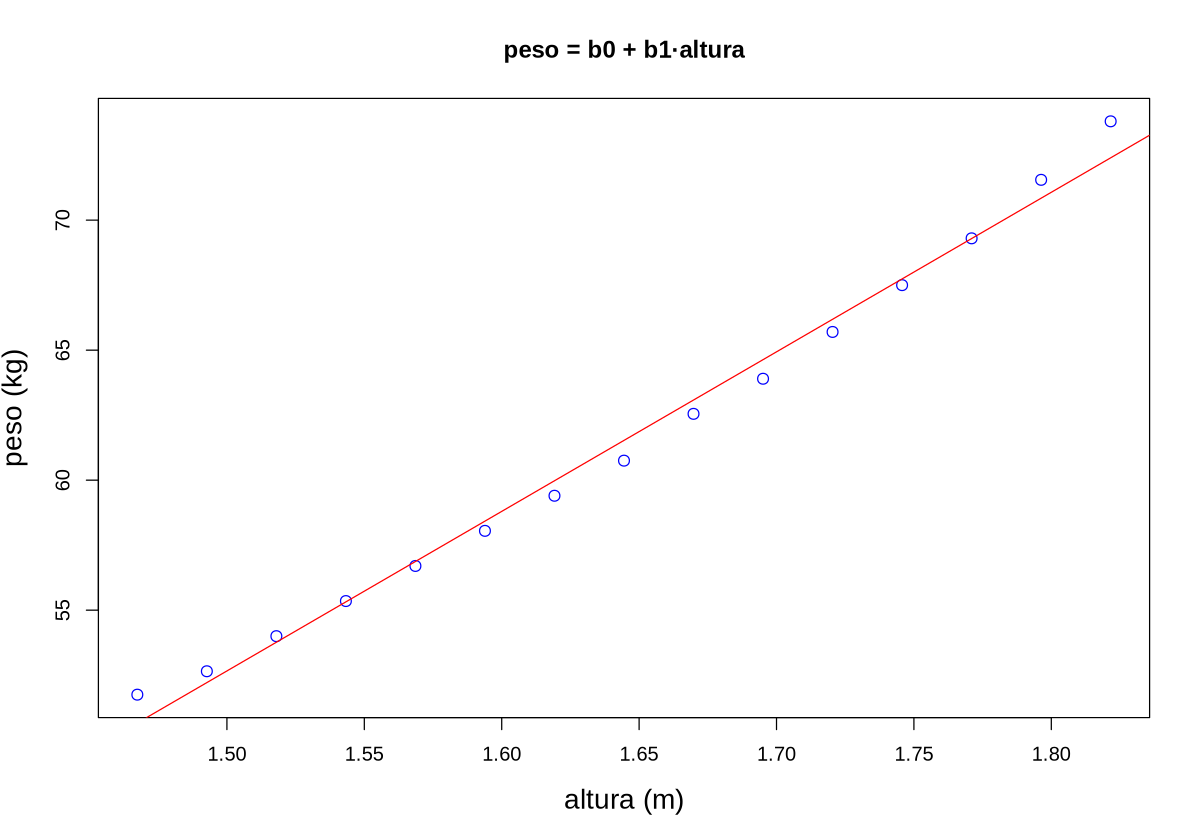

In [14]:
plot(mlh$altura, mlh$peso,  col="blue", cex=1.2, cex.lab=1.4,
     xlab="altura (m)", ylab="peso (kg)",
     main="peso = b0 + b1·altura")
abline(reg, col="red")

## Avaliação do Modelo

O modelo deve ser verificado e um processo iterativo iniciado para ajustar o modelo de modo que explique o máximo possível da variável resposta sem ser excessivamente dependente dos dados do aprendizado.

Iniciamos a avaliação do modelo verificando a distância dos dados previstos com relação as dados originais. Quanto maior a distância, mais pobre foi a modelagem.

### EAM - Erro Absoluto Médio (ou MAE - _Mean Absolute Error_)

O Erro Absoluto Médio é a média dos módulos das diferenças entre os valores previstos e os observados, ou seja:

$$ EAM(\hat{y}) = \frac{1}{n}\sum_{i=1}^{n} {|\hat{y_i} - x_i|}$$

In [15]:
# definindo como calcular o erro absoluto médio:
eam <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        resultado <- sum(abs(predito - observado)) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}

### EQM - Erro Quadrático Médio (ou MSE - _Mean Squared Error_)

O Erro Quadrático Médio é a média dos quadrados das diferenças entre os valores previstos e os observados, ou seja:

$$ EQM(\hat{y}) = \frac{1}{n}\sum_{i=1}^{n} {(\hat{y_i} - x_i)^2}$$

In [16]:
# definindo como calcular o erro quadrático médio:
eqm <- function (predito, observado) {
    if (length(predito) == length(observado)) {
        diferenca <- predito - observado
        resultado <- sum(diferenca * diferenca) / length(observado)
        return (resultado)
    } else { 
        return (NA) 
    }
}

In [17]:
predito <- fitted(reg) 
print(data.frame(mlh$peso, predito, dif=mlh$peso-predito))

   mlh.peso predito     dif
1      51.8    50.7  1.0875
2      52.6    52.2  0.4350
3      54.0    53.8  0.2325
4      55.4    55.3  0.0300
5      56.7    56.9 -0.1725
6      58.1    58.4 -0.3750
7      59.4    60.0 -0.5775
8      60.8    61.5 -0.7800
9      62.6    63.1 -0.5325
10     63.9    64.6 -0.7350
11     65.7    66.2 -0.4875
12     67.5    67.7 -0.2400
13     69.3    69.3  0.0075
14     71.5    70.8  0.7050
15     73.8    72.4  1.4025


In [18]:
sum(abs(predito - mlh$peso)) / 15
eam(predito, mlh$peso)

[1] 0.52

[1] 0.52

In [19]:
sum((predito - mlh$peso)^2) / 15
eqm(predito, mlh$peso)

[1] 0.408

[1] 0.408

Pode-se, então, construir uma tabela avaliando a adequação do modelo:

| modelo | EAM | EQM | R² |
| :- | -: | -: | -: |
| `peso` = -39,38 + 61,36 ·`altura`| 0,52 | 0,40 | 0,9903 |

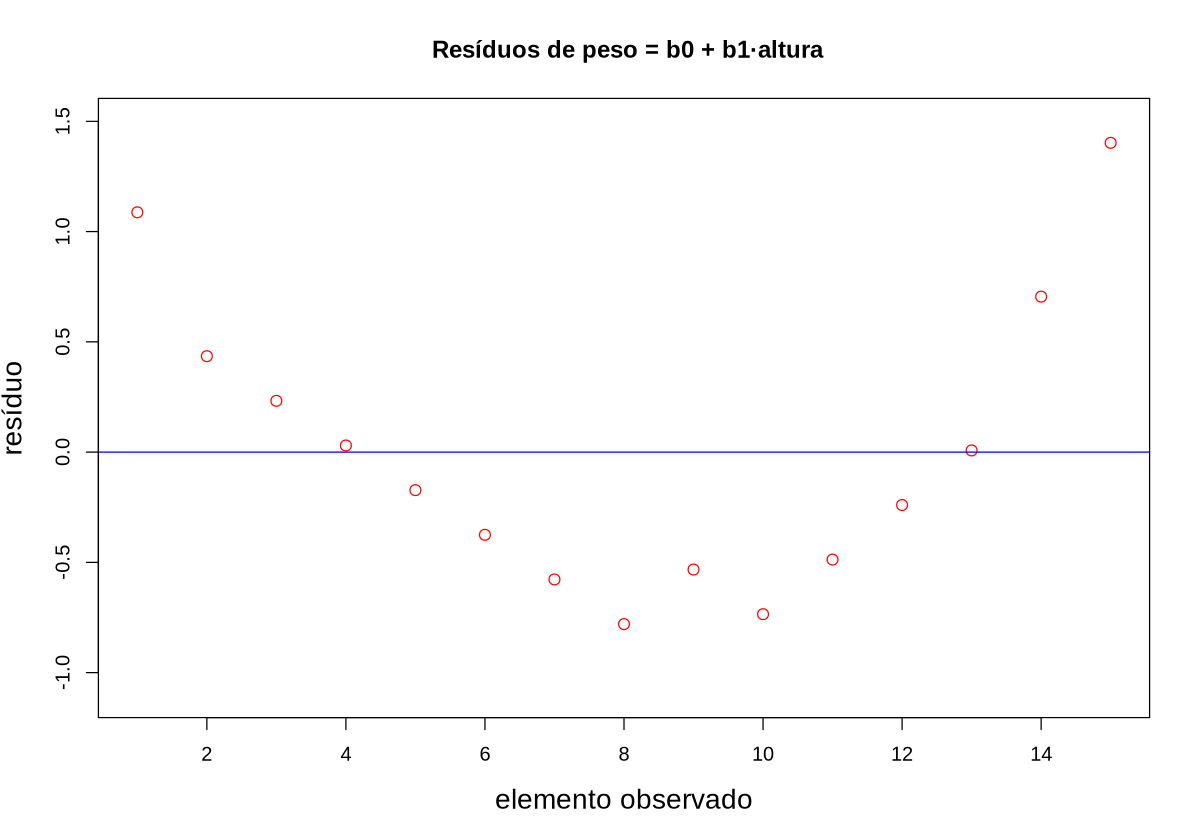

In [20]:
plot(reg$residuals, col="red", cex=1.2, cex.lab=1.4,
     xlab="elemento observado", ylab="resíduo", 
     ylim=c(-1.1,1.5), main=" Resíduos de peso = b0 + b1·altura")
abline(h=0.0, col="blue")

Os resíduos, que supostamente deveriam apenas ser valores aleatórios ao redor de 0, apresentam um claro comportamento de parábola. É uma clara indicação que o modelo falha em capturar uma possível componente em $x^2$.

Aderindo uma regressão com componente ao quadrado:

In [21]:
reg2 <- lm(formula=peso ~ altura + I(altura^2), data=mlh)

A nova regressão modela a expressão:  
$y_i = b_0 + b_1 x_i + b_2 x_i^2$  
$y_i$ - elemento _i_ estimado (predito)  
$b_0$ - constante linear estimada  
$b_1$ - coeficiente de inclinação estimado  
$b_2$ - coeficiente do termo ao quadrado  
$x_i$ - elemento $i$ da variável independente amostral $x$

In [23]:
reg2


Call:
lm(formula = peso ~ altura + I(altura^2), data = mlh)

Coefficients:
(Intercept)       altura  I(altura^2)  
      117.8       -130.7         58.4  


O novo ajuste propõe a regressão:  
`peso` = 117,8 -130,7 ·`altura` + 58,4 ·`altura`²  

In [22]:
summary(reg2)


Call:
lm(formula = peso ~ altura + I(altura^2), data = mlh)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.22923 -0.13325 -0.00423  0.12877  0.26868 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)    117.8       11.3   10.39  2.4e-07 ***
altura        -130.7       13.8   -9.45  6.6e-07 ***
I(altura^2)     58.4        4.2   13.89  9.3e-09 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.173 on 12 degrees of freedom
Multiple R-squared:  0.999,	Adjusted R-squared:  0.999 
F-statistic: 1.14e+04 on 2 and 12 DF,  p-value: <2e-16


---

Informações úteis: 

Valores estimados dos parâmetros:  

| parâmetro | valor | significância estatística <br>(é importante para a variável dependente?) | | 
| :- | -: | -: | -: |
| $b_0$ | 117,8  | $2,4.10^{-7}$ < 0,05 ? |**→** sim | 
| $b_1$ (`altura`) | $-130,7$ | $6,6.10^{-7}$ < 0,05 ? |**→** sim | 
| $b_2$ (`altura²`) | $58,4$ | $9,3.10^{-9}$ < 0,05 ? |**→** sim | 
: {tbl-colwidths="[35,10,52,8]"}

O valor do coeficiente de correlação $R^2$  (ajustado) é 0,999, significando que o modelo explica 99,9% dos erros.

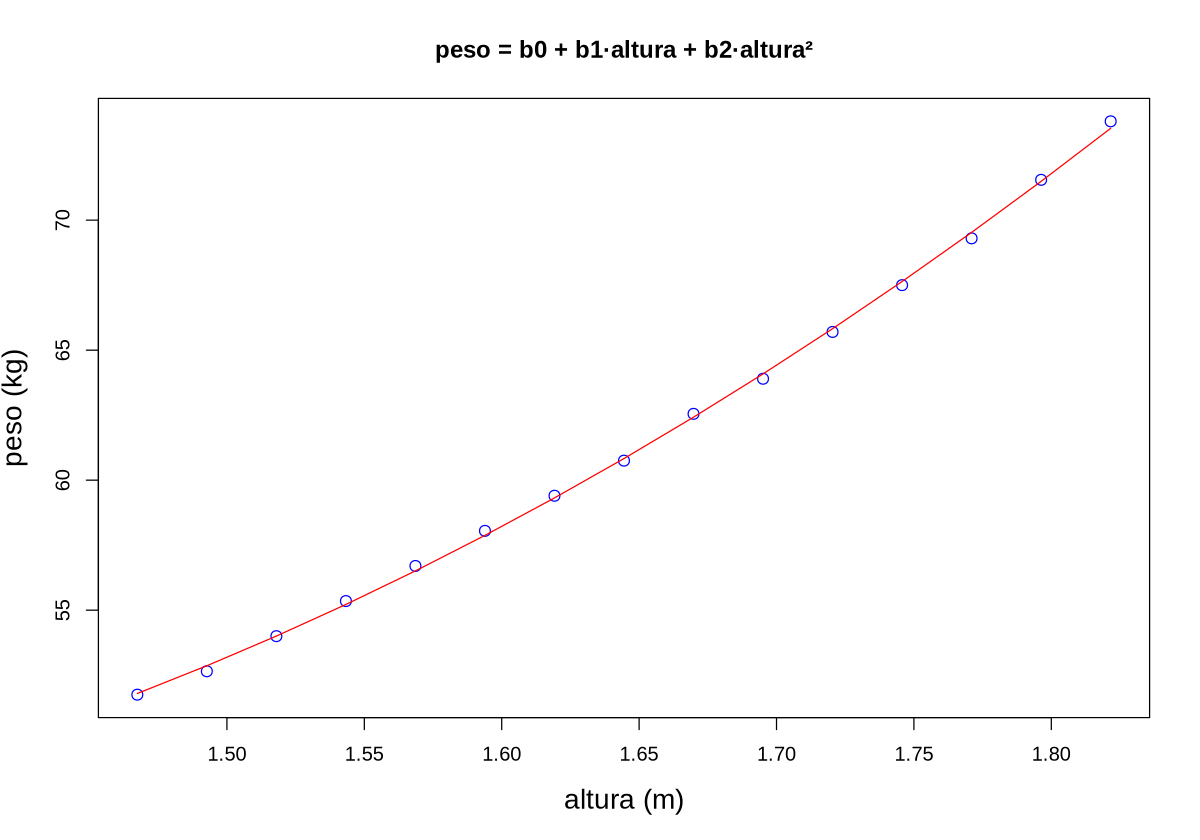

In [24]:
plot(mlh$altura, mlh$peso, 
     col="blue", cex=1.2, cex.lab=1.4,
     xlab="altura (m)", ylab="peso (kg)", 
     main="peso = b0 + b1·altura + b2·altura²")
lines(mlh$altura, fitted(reg2), col="red")

---

In [ ]:
predito2 <- fitted(reg2)
eam(predito2, mlh$peso)

In [ ]:
eqm(predito2, mlh$peso)

---

Vamos comparar os modelos:

| modelo | EAM | EQM | $R^2$ |
| :- | -: | -: | -: |
| `peso` = -32,38 + 50,45 ·`altura`| 0,52 | 0,40 | 0,9903 |
| `peso` = 96,9 -107,5 ·`altura` + 48,0 ·`altura`² | 0,14 | 0,02 | 0,9990 |
: {tbl-colwidths="[64,12,12,12]"}

Avaliando os resíduos do novo modelo:

In [ ]:
plot(reg2$residuals, xlab="elemento observado", ylab="resíduo", 
     col="red", ylim=c(-1.1,1.5), cex.lab=1.4, cex=1.2,
     main="Resíduos de peso = b0 + b1·altura + b2·altura²")
abline(h=0.0, col="blue")

Como exercício didático, poderíamos verificar se não há uma componente cúbica (na forma de `altura`³), o que seria forçar demais os poucos dados à procura de explicação...

In [ ]:
reg3 <- lm(formula=peso ~ altura + I(altura^2) + I(altura^3), data=mlh)

In [ ]:
reg3

In [ ]:
summary(reg3)

In [ ]:
plot(mlh$altura, mlh$peso, col="blue", cex=1.2, cex.lab=1.4,
     xlab="altura (m)", ylab="peso (kg)", 
     main="peso = b0 + b1·altura + b2·altura² + b3·altura³")
lines(mlh$altura, fitted(reg3), col="red")

In [ ]:
plot(reg3$residuals, col="red", cex=1.2, cex.lab=1.4,
     xlab="elemento observado", ylab="resíduo", 
     ylim=c(-1.1,1.5),
     main="Resíduos de peso = b0 + b1·altura + b2·altura² + b3·altura³")
abline(h=0.0, col="blue")

Apesar de aparentemente ter obtido a regressão "perfeita", seria absurdo propor uma explicação utilizando `altura`³ para 15 dados.  
Além disso, poderíamos estar passando para um problema de _overfitting_ (sobreajuste ou superajuste).

## Referências

>**Probabilidade e Estatística para Engenharia e Ciências** - 3. ed. / 2006 - ( Livros )
DEVORE, Jay L. ed. São Paulo: Cengage Learning, 2019. xiii, 692 p. ISBN 9788522104598.  
Número de chamada: 519.2 D512p 3. ed. (PE)